In [4]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
 
URL = ("https://raw.githubusercontent.com/justmarkham/"
       "pycon-2016-tutorial/master/data/sms.tsv")
sms = pd.read_csv(URL, sep="\t", header=None, names=["label", "message"])
X_sms, y_sms = sms["message"], (sms["label"] == "spam").astype(int)
Xtr, Xte, ytr, yte = train_test_split(X_sms, y_sms, test_size=0.25,
                                      stratify=y_sms, random_state=42)
pipe = Pipeline([("tfidf", TfidfVectorizer()),
                 ("clf", LogisticRegression(max_iter=1000))]).fit(Xtr, ytr)

In [5]:
# 1 — Ma trận nhầm lẫn và bốn ô
from sklearn.metrics import confusion_matrix

y_pred = pipe.predict(Xte)
cm = confusion_matrix(yte, y_pred);
print(cm)
tn, fp, fn, tp = cm.ravel();
print("TN", tn, "| FP", fp, "| FN", fn, "| TP", tp)

[[1206    0]
 [  39  148]]
TN 1206 | FP 0 | FN 39 | TP 148


In [6]:
#  Tính tay precision, recall, F1
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

p = tp / (tp + fp)
r = (tp) / (tp + fn)
f1 = (2 * p * r) / (p + r)

print("tính tay: ", round(p,3), round(r,3), round(f1,3))
print("sklearn: ", round(precision_score(yte,y_pred),3), round(recall_score(yte,y_pred),3), round(f1_score(yte,y_pred),3))
print("accuracy :", round(accuracy_score(yte, y_pred), 3),
      "| baseline:", round(1 - yte.mean(), 3))  

tính tay:  1.0 0.791 0.884
sklearn:  1.0 0.791 0.884
accuracy : 0.972 | baseline: 0.866


In [7]:
# classification_report
from sklearn.metrics import classification_report
print(classification_report(yte,y_pred,target_names=["ham","spam"],digits=3))
# Bảng precision, recall, F1, support cho từng lớp, kèm accuracy, macro avg, weighted avg.
# support: Số mẫu thật của lớp đó trong tập chấm

# Macro avg: trung bình cộng, mỗi lớp nặng như nhau
# Cộng điểm của hai lớp rồi chia 2, không quan tâm lớp nào đông hay ít:
# precision = (0.969 + 1.000) / 2 = 0.984
# recall    = (1.000 + 0.791) / 2 = 0.896
# f1        = (0.984 + 0.884) / 2 = 0.934

# Weighted avg: trung bình theo số đông
# Mỗi lớp được tính theo tỉ lệ số mẫu của nó: ham chiếm 1206/1393 ≈ 86,6%, spam chiếm 187/1393 ≈ 13,4%.
# precision = 0.866 × 0.969 + 0.134 × 1.000 = 0.973
# recall    = 0.866 × 1.000 + 0.134 × 0.791 = 0.972
# f1        = 0.866 × 0.984 + 0.134 × 0.884 = 0.971

              precision    recall  f1-score   support

         ham      0.969     1.000     0.984      1206
        spam      1.000     0.791     0.884       187

    accuracy                          0.972      1393
   macro avg      0.984     0.896     0.934      1393
weighted avg      0.973     0.972     0.971      1393



In [13]:
proba = pipe.predict_proba(Xte)[:, 1]             # cột 1 = xác suất là spam
print(proba)
print("ngưỡng  precision  recall  báo_nhầm  bỏ_sót")
for th in [0.5, 0.4, 0.3, 0.2, 0.1]:
    pr = (proba >= th).astype(int)                # tự áp ngưỡng
    c = confusion_matrix(yte, pr)
    print(f"{th:<7} {precision_score(yte, pr):.3f}      {recall_score(yte, pr):.3f}"
          f"   {c[0, 1]:>6}  {c[1, 0]:>6}")

[0.05338976 0.54772646 0.0368018  ... 0.74696173 0.0729508  0.07868957]
ngưỡng  precision  recall  báo_nhầm  bỏ_sót
0.5     1.000      0.791        0      39
0.4     0.988      0.850        2      28
0.3     0.971      0.888        5      21
0.2     0.907      0.936       18      12
0.1     0.625      0.979      110       4


đã lưu ../figures/b05_confusion.png


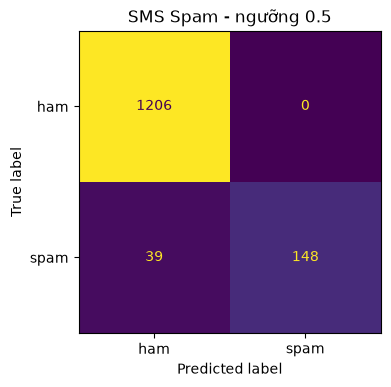

In [14]:
# Vẽ và lưu ma trận nhầm lẫn
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
 
fig, ax = plt.subplots(figsize=(4, 4))
ConfusionMatrixDisplay.from_predictions(yte, y_pred, display_labels=["ham", "spam"],
                                        ax=ax, colorbar=False)
ax.set_title("SMS Spam - ngưỡng 0.5")
fig.tight_layout()
fig.savefig("../figures/b05_confusion.png", dpi=150)
print("đã lưu ../figures/b05_confusion.png")